In [2]:
import pandas as pd
import datetime as dt
import numpy as np 
import glob
import matplotlib.pyplot as plt 
import matplotlib.patches as patches

from matplotlib.ticker import AutoMinorLocator


from JunoPy.spice import InitSpiceKernels, get_juno_position
from JunoPy.mag import MagData

# Get Juno trajectory in JUNO_MAG_VIP4 coordinate
InitSpiceKernels()
start = dt.datetime(2016, 6, 20, 17, 30)
end   = dt.datetime(2020, 7, 27, 16)
time_array = pd.date_range(
        start=start, end=end, freq='H').to_pydatetime().tolist()
position, _ = get_juno_position(time_array, coordsystem='JUNO_MAG_VIP4')


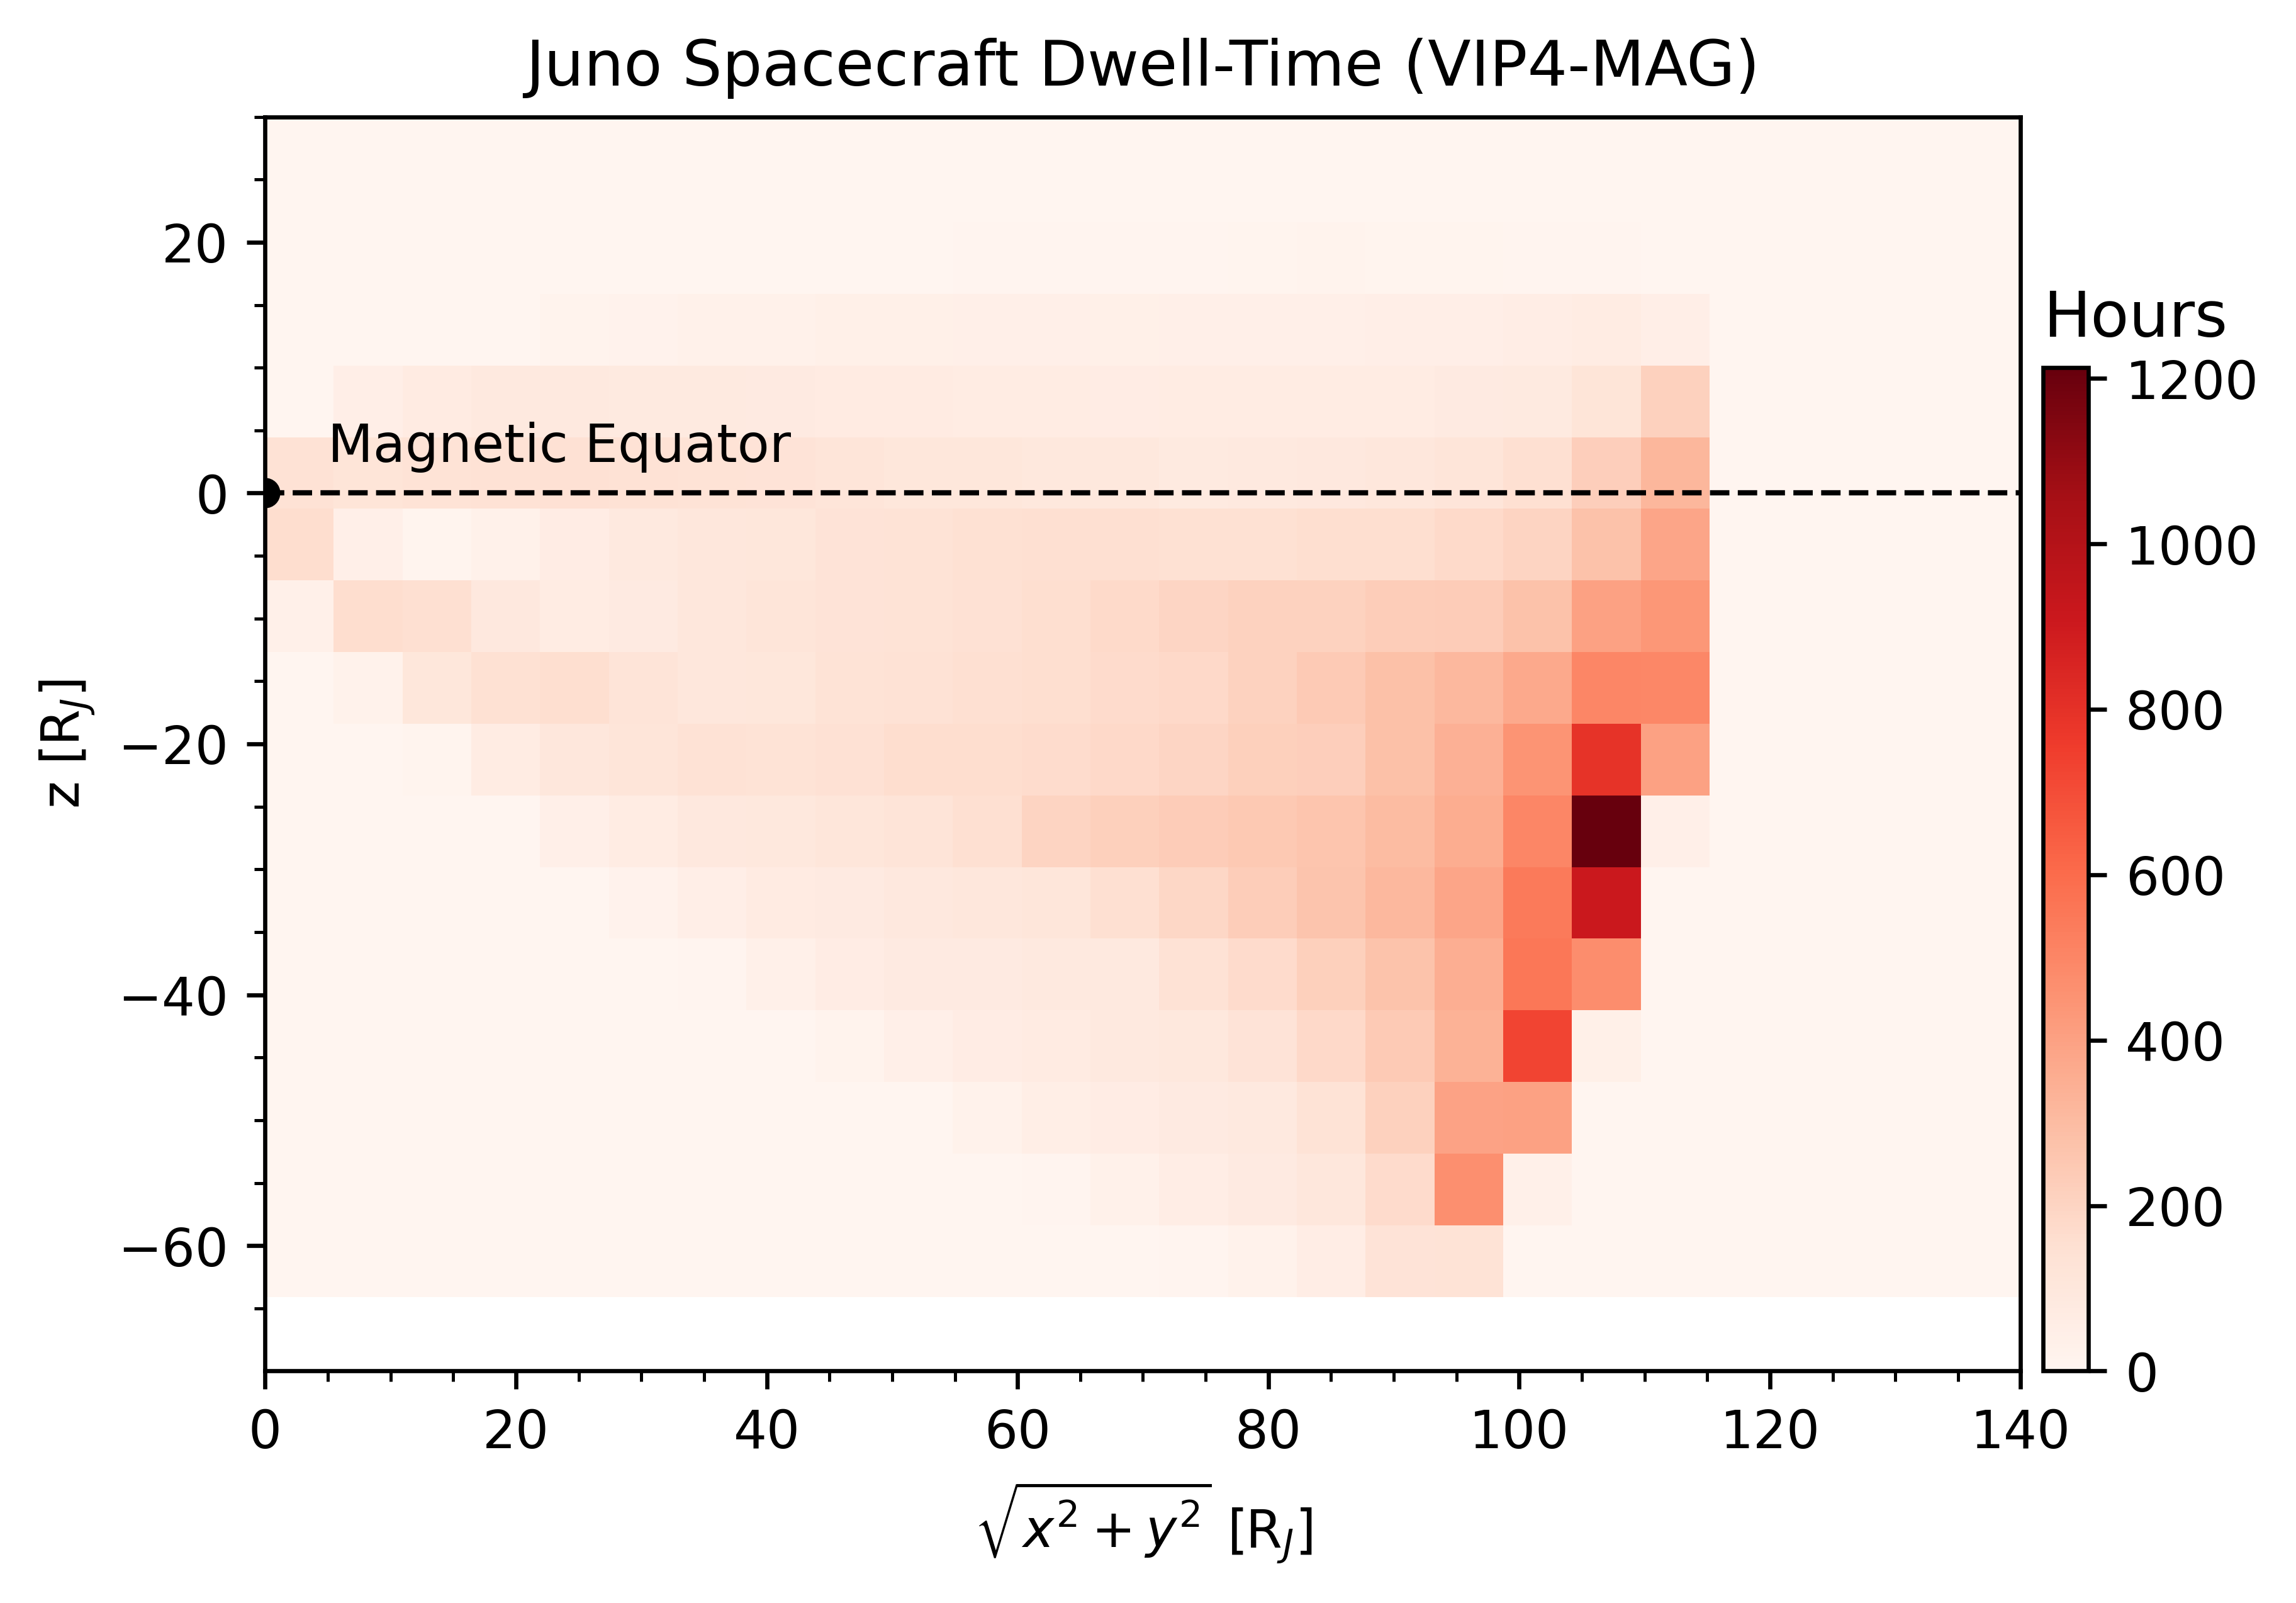

In [3]:
# Plot the trajectory
fig = plt.figure(figsize=(6,8), dpi=600)
ax = plt.subplot(111)

mp = ax.hist2d(np.sqrt(position[:, 0]**2 + position[:, 1]**2), position[:, 2], bins=[29, 21], cmap='Reds')

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
# ax.grid('on', which='minor', lw=0.5, ls='dotted')
# ax.grid(color='k', ls='dashed', lw=0.25)

ax.set_xlabel('$\sqrt{x^2 + y^2}$ [R$_J$]')
ax.set_ylabel('z [R$_J$]')

ax.set_xlim([0, 140])
ax.set_ylim([-70, 30])
ax.set_aspect('equal', share=True)

size = 0.02
bbox = ax.get_position()
cax = ax.figure.add_axes([bbox.x1 + 0.01, bbox.y0, 0.02, 0.8 * (bbox.y1- bbox.y0)])
cbar = ax.figure.colorbar(mp[3], cax=cax)
cax.set_title('Hours', loc='left')
        
ax.add_artist(plt.Circle((0, 0), 1.0, color='k', zorder=5))
ax.axhline(0, ls='dashed', color='k', lw=1.0)
ax.text(5, 2.5, 'Magnetic Equator')

ax.set_title('Juno Spacecraft Dwell-Time (VIP4-MAG)')
fig.savefig('out_images/juno-dwell-time.png', bbox_inches='tight')

In [4]:
rho = np.sqrt(position[:, 0]**2 + position[:, 1]**2)
z = position[:, 2] * 1.0

z = z[rho > 40]
rho = rho[rho > 40]

rho = rho[(z > -2) & (z < 2)]
z = z[(z > -2) & (z < 2)]

len(rho)


1374

In [12]:
# Get Juno trajectory in JUNO_MAG_VIP4 coordinate (one orbit)
InitSpiceKernels()

start = dt.datetime.strptime('2017-230T00:00:00', '%Y-%jT%H:%M:%S')
end   = dt.datetime.strptime('2017-250T23:59:59', '%Y-%jT%H:%M:%S')
time_array = pd.date_range(
        start=start, end=end, freq='T').to_pydatetime().tolist()
position, _ = get_juno_position(time_array, coordsystem='JUNO_MAG_VIP4')


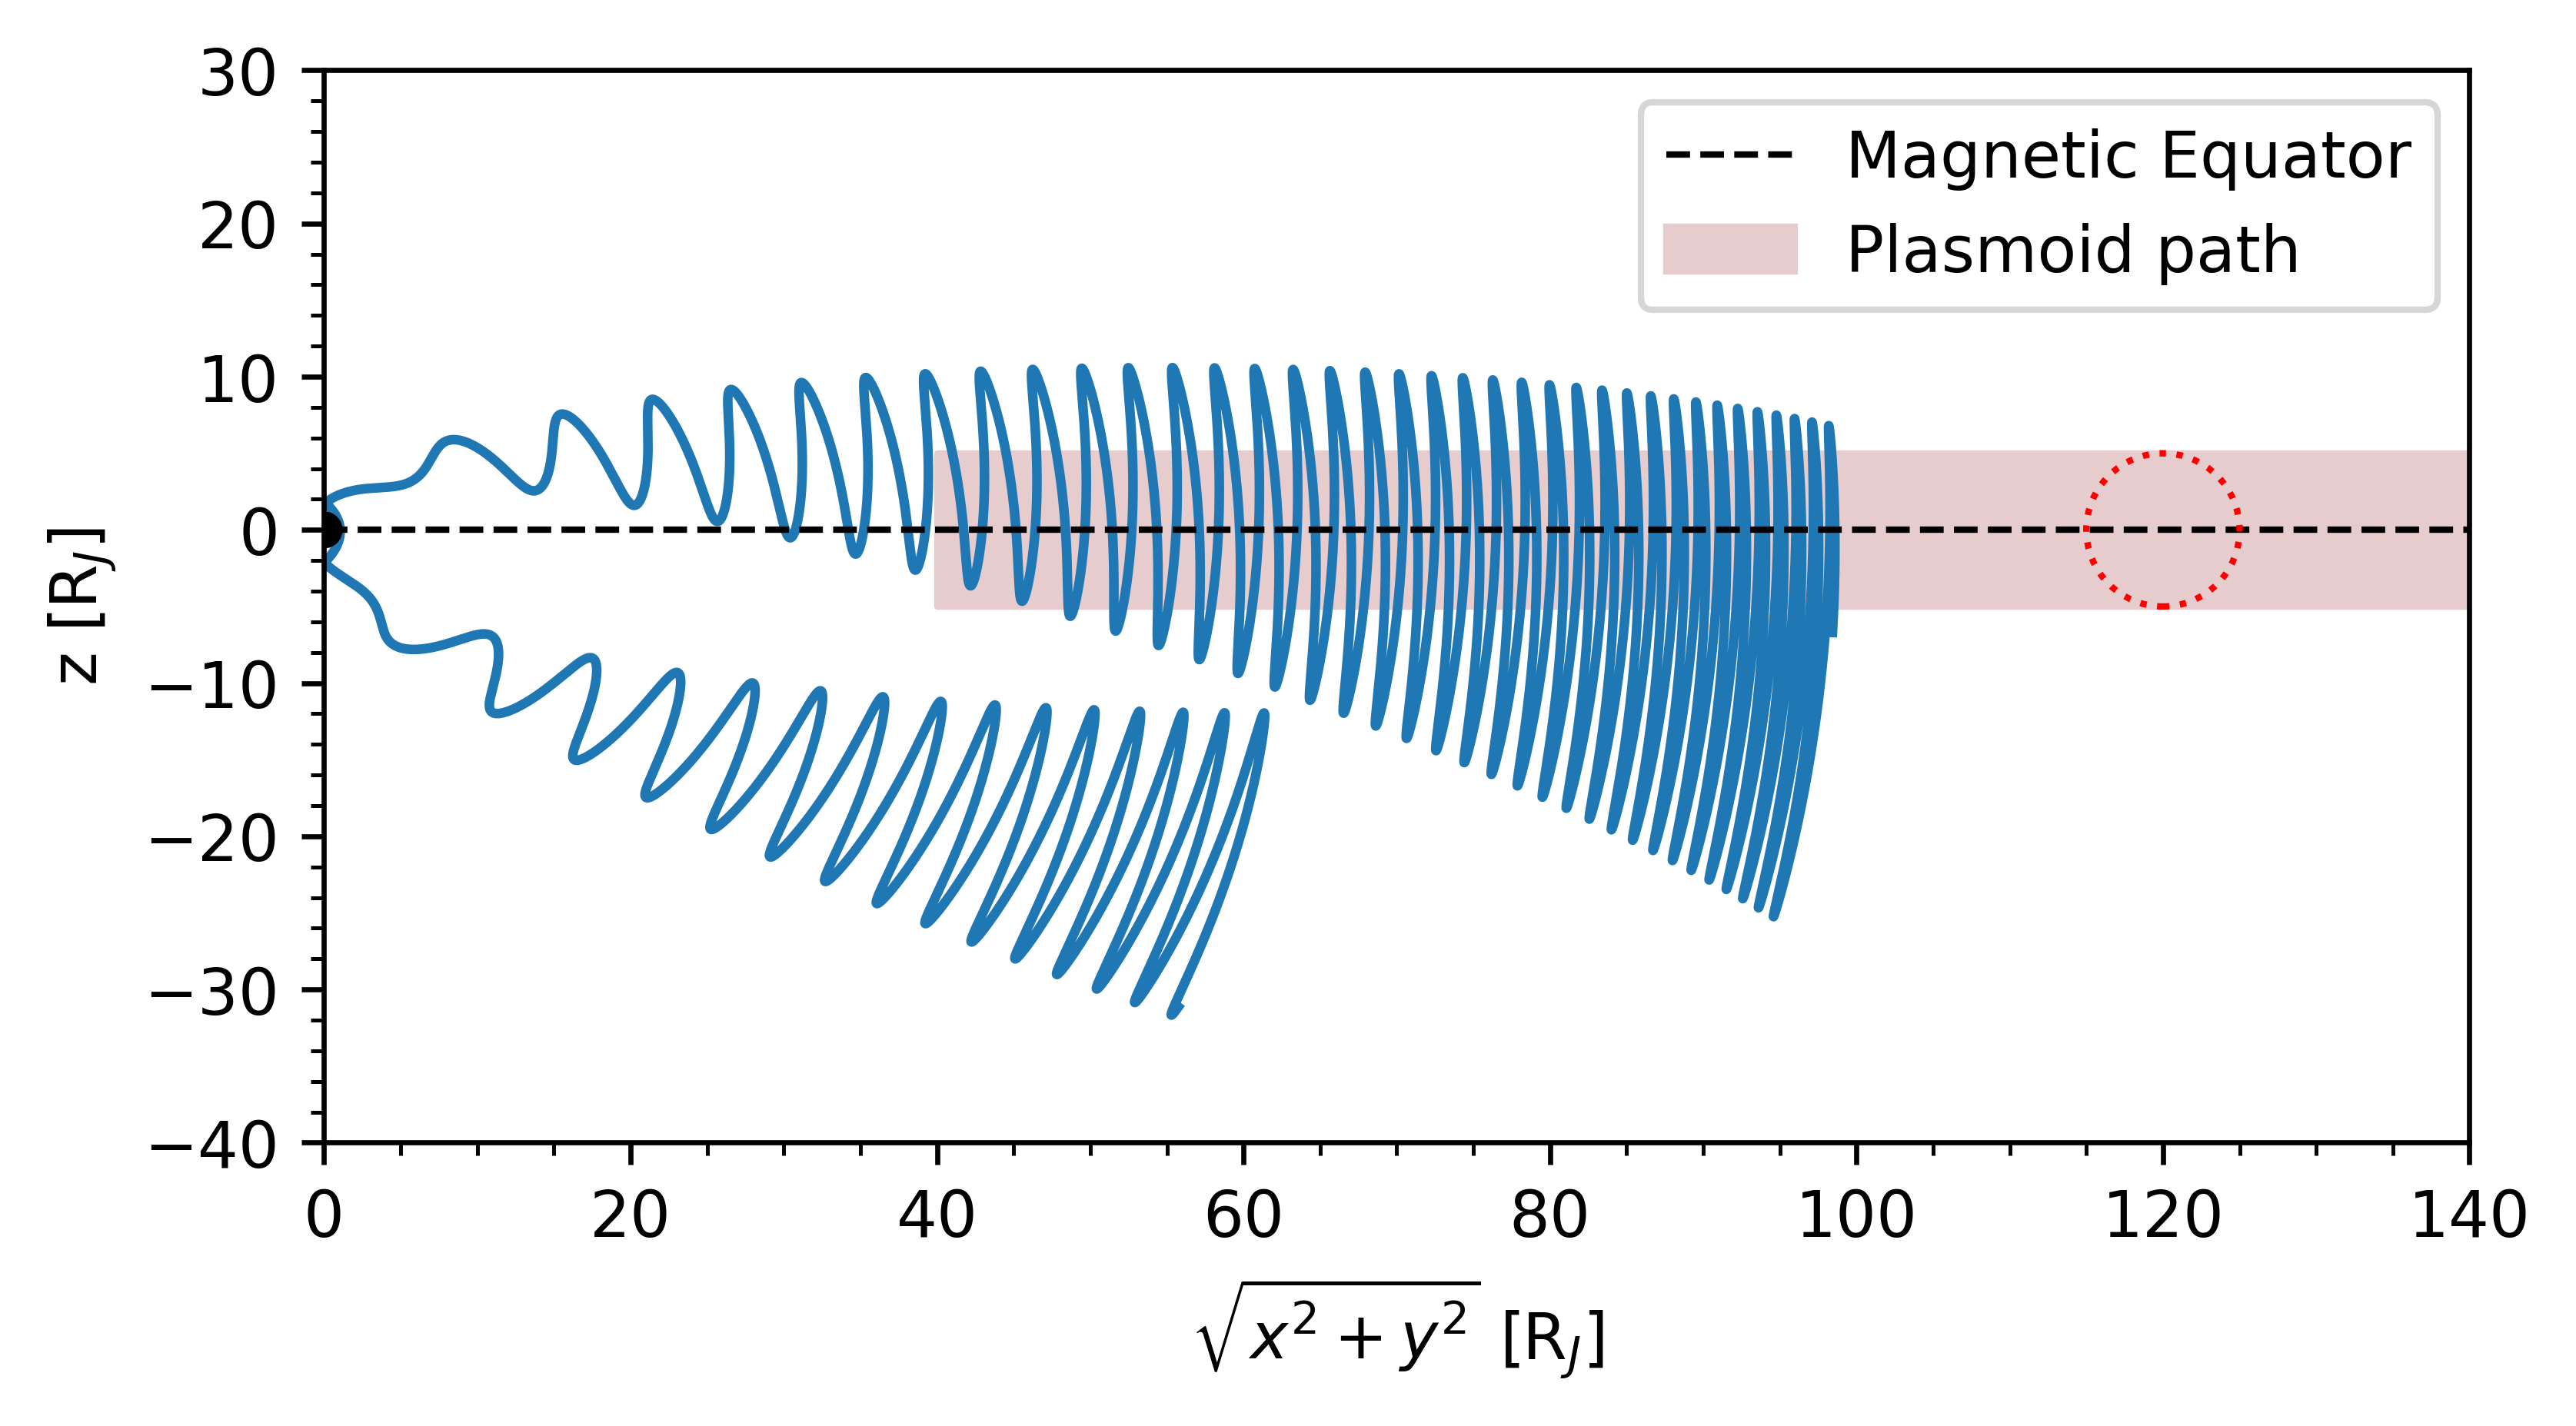

In [42]:
# Plot the trajectory
fig = plt.figure(figsize=(6,8), dpi=600)
ax = plt.subplot(111)

ax.plot(np.sqrt(position[:, 0]**2 + position[:, 1]**2), position[:, 2])

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
# ax.grid('on', which='minor', lw=0.5, ls='dotted')
# ax.grid(color='k', ls='dashed', lw=0.25)

ax.set_xlabel('$\sqrt{x^2 + y^2}$ [R$_J$]')
ax.set_ylabel('z [R$_J$]')

ax.set_xlim([0, 140])
ax.set_ylim([-40, 30])
ax.set_aspect('equal', share=True)

        
ax.add_artist(plt.Circle((0, 0), 1.0, color='k', zorder=5))
ax.axhline(0, ls='dashed', color='k', lw=1.0, label='Magnetic Equator')

ax.fill_between(np.linspace(40, 140, 100), -5, y2=5, color=[0.9, 0.8, 0.8], label='Plasmoid path')
ax.add_artist(plt.Circle((120, 0), 5.0, zorder=5, ls='dotted', color='r', fill=False))

# ax.text(100, 1.0, 'Magnetic Equator')

ax.legend()
# ax.set_title('Juno Spacecraft Dwell-Time (VIP4-MAG)')
fig.savefig('out_images/juno-trajec-vip4-mag.png', bbox_inches='tight')